# Deep Learning for Default Prediction
**IB98D0 Advanced Data Analytics — Group Assignment**

**Framework**: PyTorch  
**Task**: Binary classification — predict `loan_is_bad` (1 = default, 0 = repaid)  
**Dataset**: LendingClub 50,000 loans (2012–2013)  

In [2]:
# Verify GPU availability
import torch
print('Using device:', torch.device('cuda' if torch.cuda.is_available() else 'cpu'))

Using device: cuda


In [3]:
# Standard library imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# PyTorch core
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Scikit-learn utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, average_precision_score,
    accuracy_score, precision_score,
    recall_score, f1_score
)

# Reproducibility seeds
torch.manual_seed(10086)
np.random.seed(10086)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


In [4]:
# Upload the LendingClub dataset to this Colab session
from google.colab import files
uploaded = files.upload()

Saving early_2012_2013_loan_sample_with_outcome.csv to early_2012_2013_loan_sample_with_outcome.csv


---
## Prediction Task and Data Split

**Task**: Binary classification — predict `loan_is_bad` (1 = default/charged-off, 0 = fully repaid)  
**Split**: Stratified 70 / 15 / 15 (train / validation / test) using `random_state=10086`  
Stratification preserves the 15.63% default rate across all three sets.  
All features are sourced from data available at origination — no post-issuance data leakage.

In [5]:
# Load dataset
df = pd.read_csv('early_2012_2013_loan_sample_with_outcome.csv', low_memory=False)

# Data cleaning
# revol_util is stored as a string with a % suffix — strip and convert to float (0–100 scale)
df['revol_util_clean'] = pd.to_numeric(
    df['revol_util'].astype(str).str.replace('%', '', regex=False),
    errors='coerce'
)
df['emp_length']       = df['emp_length'].fillna(df['emp_length'].median())
df['revol_util_clean'] = df['revol_util_clean'].fillna(df['revol_util_clean'].median())
df['home_ownership']   = df['home_ownership'].replace('NONE', 'OTHER')  # consolidate rare category

# Feature engineering
# Sub-grade ordinal: A1=0, A2=1 ... G5=34 (35 levels)
# Captures LendingClub's internal credit scoring more precisely than letter grade alone
grade_base = {'A': 0, 'B': 5, 'C': 10, 'D': 15, 'E': 20, 'F': 25, 'G': 30}
df['sub_grade_num'] = df['sub_grade'].apply(
    lambda sg: grade_base.get(str(sg)[0], 0) + int(str(sg)[1])
    if pd.notna(sg) else 0
)

# Ratio features — capture financial burden relative to income
df['loan_to_income']        = df['loan_amnt'] / (df['annual_inc'] + 1)          # loan exposure
df['installment_to_income'] = df['installment'] / (df['annual_inc'] / 12 + 1)   # monthly burden

# Log transforms — reduce right-skew in income and revolving balance
df['log_annual_inc'] = np.log1p(df['annual_inc'])
df['log_revol_bal']  = np.log1p(df['revol_bal'])

# Informative missingness: mths_since_last_delinq is only populated when a delinquency occurred
# ~isna() = 1 means the borrower HAS a delinquency record — a risky signal
df['has_delinq_history'] = (~df['mths_since_last_delinq'].isna()).astype(float)

# ── Build feature matrix ───────────────────────────────────────────────
# Only origination-time features included — no post-issuance data leakage
numeric_features = [
    'loan_amnt', 'int_rate', 'installment', 'annual_inc', 'dti',
    'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec',
    'revol_bal', 'revol_util_clean', 'total_acc', 'emp_length',
    'term', 'acc_now_delinq',
    'sub_grade_num',          # ordinal risk grade
    'loan_to_income',         # loan exposure relative to capacity
    'installment_to_income',  # monthly payment burden
    'log_annual_inc',         # log-transformed income
    'log_revol_bal',          # log-transformed revolving balance
    'has_delinq_history',     # informative missingness flag
]
categorical_features = ['home_ownership', 'verification_status', 'purpose']

# One-hot encode categorical features (drop_first avoids multicollinearity)
df_cat = pd.get_dummies(df[categorical_features], drop_first=True, dtype=float)

X = pd.concat([df[numeric_features], df_cat], axis=1)
y = df['loan_is_bad'].astype(int).values

print(f'Total features : {X.shape[1]}  ({len(numeric_features)} numeric, {df_cat.shape[1]} categorical)')
print(f'Default rate   : {y.mean():.4f}')
print(f'has_delinq_history mean: {df["has_delinq_history"].mean():.3f}  '
      f'(1 = has prior delinquency, 0 = never delinquent)')

Total features : 38  (21 numeric, 17 categorical)
Default rate   : 0.1563
has_delinq_history mean: 0.437  (1 = has prior delinquency, 0 = never delinquent)


In [6]:
# Stratified 70 / 15 / 15 split
# stratify=y ensures each split preserves the 15.63% minority default rate
# test_size=0.15 gives 15% test; 0.1765 of remainder gives 15% of total for validation
X_temp, X_test_df, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=10086, stratify=y
)
X_train_df, X_val_df, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.1765, random_state=10086, stratify=y_temp
)

print(f'Train {X_train_df.shape[0]}  |  Val {X_val_df.shape[0]}  |  Test {X_test_df.shape[0]}')
print(f'Default rate — Train: {y_train.mean():.4f}  |  Val: {y_val.mean():.4f}  |  Test: {y_test.mean():.4f}')

Train 34998  |  Val 7502  |  Test 7500
Default rate — Train: 0.1563  |  Val: 0.1562  |  Test: 0.1563


In [7]:
# Feature scaling
# fit_transform on train only — prevents data leakage into val/test
# centres each feature at 0 with unit variance for stable gradient descent
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_df)   # fit HERE only
X_val_scaled   = scaler.transform(X_val_df)         # apply same transform
X_test_scaled  = scaler.transform(X_test_df)        # apply same transform

---
## Model Design and Training

**Architecture**: 4-layer feedforward MLP — Input → 128 → 64 → 32 → 1 (logit output)  
**Regularisation**: BatchNorm + Dropout (0.3 / 0.3 / 0.2) + L2 weight decay (1e-4 via Adam)  
**Loss**: `BCEWithLogitsLoss` with `pos_weight = 5.40×` to address the 84:16 class imbalance  
**Optimiser**: Adam (lr=0.001) with `ReduceLROnPlateau` (factor=0.5, patience=5)  
**Early stopping**: patience=15 epochs, monitored on validation AUC

Input features : 38
LoanMLP(
  (net): Sequential(
    (0): Linear(in_features=38, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=32, out_features=1, bias=True)
  )
)

Class imbalance — pos_weight: 5.40x (defaults penalised 5.4x more than repaid loans)
Epoch   1 | Loss: 1.1303 | Train AUC: 0.6758 | Val AUC: 0.6823 | Best: 0.6823 | LR: 1.00e-03
Epoch   2 | Loss: 1.1046 | Train AUC: 0.6791 | Val AUC: 0.6828 | Best: 0.6828 | LR: 1.00

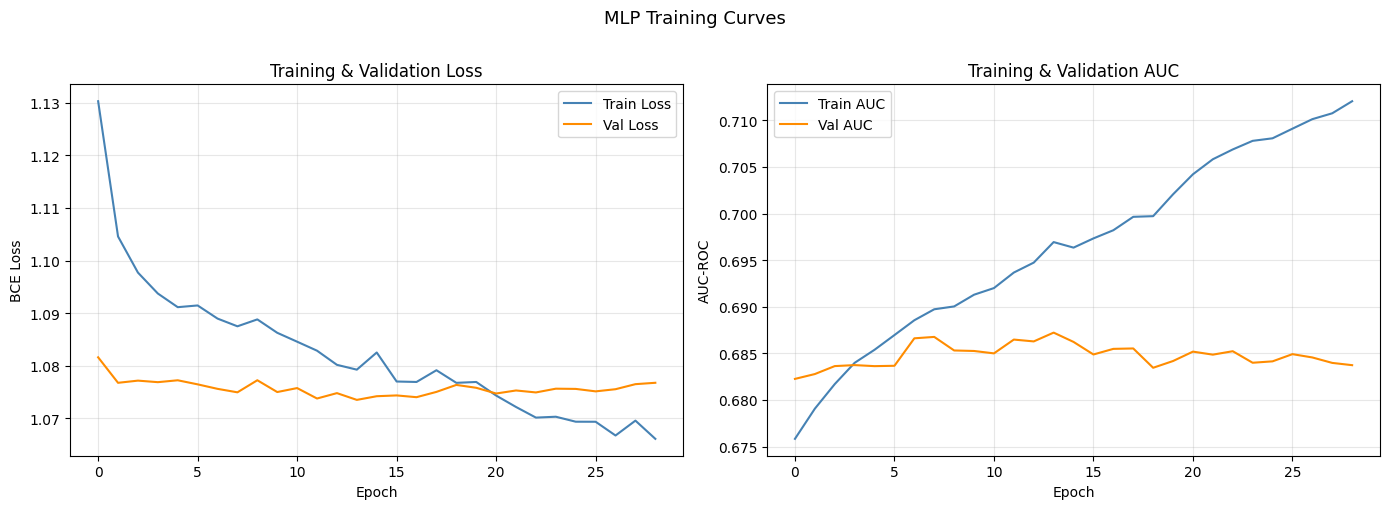


Final best Val AUC : 0.6872
Epochs trained     : 29
L2 weight decay    : 1e-4  (applied via Adam optimiser)
pos_weight         : 5.40x


In [8]:
# Model definition
class LoanMLP(nn.Module):
    """
    3-hidden-layer feedforward MLP for binary loan default prediction.
    Architecture: input → 128 → 64 → 32 → 1 (logit)
    Each hidden layer: Linear → BatchNorm → ReLU → Dropout
    """
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            # Layer 1: 128 neurons, Dropout=0.3
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
            # Layer 2: 64 neurons, Dropout=0.3
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),  nn.ReLU(), nn.Dropout(0.3),
            # Layer 3: 32 neurons, Dropout=0.2 (lighter — closer to output)
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),  nn.ReLU(), nn.Dropout(0.2),
            # Output: single logit — sigmoid applied by BCEWithLogitsLoss
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


# Instantiate model
input_dim = X_train_scaled.shape[1]
model     = LoanMLP(input_dim).to(device)
print(f'Input features : {input_dim}')
print(model)

# Loss function — handle 84:16 class imbalance
# pos_weight = n_negatives / n_positives penalises missed defaults more heavily
# BCEWithLogitsLoss applies sigmoid internally for numerical stability
pos_weight = torch.tensor(
    [(y_train == 0).sum() / (y_train == 1).sum()],
    dtype=torch.float32
).to(device)
print(f'\nClass imbalance — pos_weight: {pos_weight.item():.2f}x '
      f'(defaults penalised {pos_weight.item():.1f}x more than repaid loans)')

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# Optimiser & scheduler
# Adam with weight_decay=1e-4 applies L2 regularisation to all parameters
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
# Halve learning rate when validation AUC plateaus for 5 consecutive epochs
scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5, min_lr=1e-6)

# DataLoaders
def make_loader(X, y, shuffle=False, batch_size=256):
    """Wrap numpy arrays in PyTorch DataLoader for batched training."""
    Xt = torch.tensor(X, dtype=torch.float32)
    yt = torch.tensor(y, dtype=torch.float32)
    return DataLoader(TensorDataset(Xt, yt), batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(X_train_scaled, y_train, shuffle=True)
val_loader   = make_loader(X_val_scaled,   y_val)

# Training loop with early stopping
EPOCHS       = 100   # maximum epochs (early stopping will terminate sooner)
PATIENCE     = 15    # stop if val AUC does not improve for 15 consecutive epochs
best_auc     = 0.0
patience_ctr = 0
best_weights = None
train_aucs,  val_aucs   = [], []
train_losses, val_losses = [], []

for epoch in range(1, EPOCHS + 1):

    # Training pass
    model.train()
    epoch_loss, n_batches = 0.0, 0
    for Xb, yb in train_loader:
        Xb, yb = Xb.to(device), yb.to(device)
        optimizer.zero_grad()
        batch_loss = criterion(model(Xb), yb)
        batch_loss.backward()
        optimizer.step()
        epoch_loss += batch_loss.item()
        n_batches  += 1
    train_losses.append(epoch_loss / n_batches)

    # Validation pass
    model.eval()
    val_loss_total, val_batches = 0.0, 0
    with torch.no_grad():
        all_preds, all_labels = [], []
        for Xb, yb in val_loader:
            Xb_d  = Xb.to(device)
            probs = torch.sigmoid(model(Xb_d)).cpu().numpy()
            vl    = criterion(model(Xb_d), yb.to(device)).item()
            all_preds.extend(probs)
            all_labels.extend(yb.numpy())
            val_loss_total += vl
            val_batches    += 1
    val_losses.append(val_loss_total / val_batches)
    val_auc = roc_auc_score(all_labels, all_preds)

    # Train AUC
    with torch.no_grad():
        tr_preds = torch.sigmoid(
            model(torch.tensor(X_train_scaled, dtype=torch.float32).to(device))
        ).cpu().numpy()
    train_auc = roc_auc_score(y_train, tr_preds)

    train_aucs.append(train_auc)
    val_aucs.append(val_auc)
    scheduler.step(val_auc)   # reduce LR if val AUC has plateaued

    # Save best weights
    if val_auc > best_auc + 1e-4:
        best_auc     = val_auc
        best_weights = {k: v.clone() for k, v in model.state_dict().items()}
        patience_ctr = 0
    else:
        patience_ctr += 1

    print(f'Epoch {epoch:3d} | Loss: {train_losses[-1]:.4f} | '
          f'Train AUC: {train_auc:.4f} | '
          f'Val AUC: {val_auc:.4f} | Best: {best_auc:.4f} | '
          f'LR: {optimizer.param_groups[0]["lr"]:.2e}')

    if patience_ctr >= PATIENCE:
        print(f'\nEarly stopping at epoch {epoch}. Best Val AUC: {best_auc:.4f}')
        break

# Restore the best-performing weights before evaluation
model.load_state_dict(best_weights)

# Training curves: Loss and AUC side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(train_losses, label='Train Loss', color='steelblue')
axes[0].plot(val_losses,   label='Val Loss',   color='darkorange')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('BCE Loss')
axes[0].set_title('Training & Validation Loss')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(train_aucs, label='Train AUC', color='steelblue')
axes[1].plot(val_aucs,   label='Val AUC',   color='darkorange')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('AUC-ROC')
axes[1].set_title('Training & Validation AUC')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.suptitle('MLP Training Curves', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'\nFinal best Val AUC : {best_auc:.4f}')
print(f'Epochs trained     : {len(train_aucs)}')
print(f'L2 weight decay    : 1e-4  (applied via Adam optimiser)')
print(f'pos_weight         : {pos_weight.item():.2f}x')

---
## Model Evaluation

Evaluate the model on the held-out test set using AUC-ROC, Average Precision, and the full classification report. Compare Policy A (rule-based, DTI ≤ 20%) vs Policy B (DTI ≤ 30%) vs Policy C (DNN threshold = 0.25). Assess performance across the three borrower clusters identified in the cluster analysis.

TEST SET PERFORMANCE
--------------------------------------------------
  AUC-ROC            : 0.6598
  Average Precision  : 0.2505
  Accuracy           : 0.6011

              precision    recall  f1-score   support

   Good Loan       0.90      0.59      0.71      6328
    Bad Loan       0.23      0.65      0.34      1172

    accuracy                           0.60      7500
   macro avg       0.56      0.62      0.53      7500
weighted avg       0.79      0.60      0.66      7500



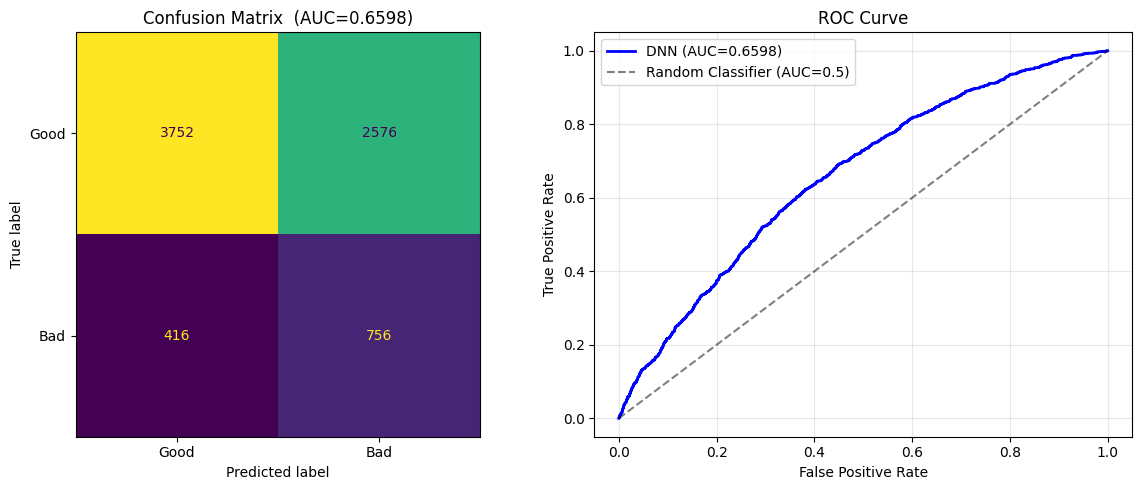

In [9]:
# Generate test set predictions
# model.eval() disables dropout and BatchNorm updates for inference
# torch.no_grad() prevents gradient computation
model.eval()
with torch.no_grad():
    y_prob = torch.sigmoid(
        model(torch.tensor(X_test_scaled, dtype=torch.float32).to(device))
    ).cpu().numpy()   # predicted default probabilities (0–1)

y_pred = (y_prob >= 0.5).astype(int)   # binary predictions at default threshold

# Performance metrics
print('TEST SET PERFORMANCE')
print('-' * 50)
print(f'  AUC-ROC            : {roc_auc_score(y_test, y_prob):.4f}')
print(f'  Average Precision  : {average_precision_score(y_test, y_prob):.4f}')
print(f'  Accuracy           : {accuracy_score(y_test, y_pred):.4f}')
print()
print(classification_report(y_test, y_pred, target_names=['Good Loan', 'Bad Loan']))

# Confusion matrix and ROC curve
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred),
    display_labels=['Good', 'Bad']
).plot(ax=axes[0], colorbar=False)
axes[0].set_title(f'Confusion Matrix  (AUC={roc_auc_score(y_test, y_prob):.4f})')

fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, 'b-', lw=2, label=f'DNN (AUC={roc_auc_score(y_test, y_prob):.4f})')
axes[1].plot([0,1],[0,1], 'k--', alpha=0.5, label='Random Classifier (AUC=0.5)')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('test_evaluation.png', dpi=150)
plt.show()

In [10]:
# Threshold analysis
# Shows the precision-recall trade-off at different decision thresholds
# Lower threshold = flag more loans as high-risk (higher recall, lower precision)
# Higher threshold = flag fewer loans (lower recall, higher precision)
print('Threshold Analysis')
print(f"{'Threshold':10} {'Accuracy':10} {'Precision':10} {'Recall':10} {'F1':10} {'Flagged':10}")
print('-' * 65)
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_p = (y_prob >= t).astype(int)
    print(f'{t:10.1f} '
          f'{accuracy_score(y_test, y_p):10.4f} '
          f'{precision_score(y_test, y_p, zero_division=0):10.4f} '
          f'{recall_score(y_test, y_p, zero_division=0):10.4f} '
          f'{f1_score(y_test, y_p, zero_division=0):10.4f} '
          f'{y_p.mean():10.1%}')

Threshold Analysis
Threshold  Accuracy   Precision  Recall     F1         Flagged   
-----------------------------------------------------------------
       0.3     0.3057     0.1762     0.9369     0.2966      83.1%
       0.4     0.4712     0.2021     0.8089     0.3234      62.5%
       0.5     0.6011     0.2269     0.6451     0.3357      44.4%
       0.6     0.7417     0.2575     0.3464     0.2954      21.0%
       0.7     0.8293     0.3402     0.0981     0.1523       4.5%


In [18]:
# DNN loan approval threshold sweep
# Approve loans where predicted default probability is BELOW the threshold
# (opposite direction to the rejection threshold above)
# Shows how approval volume and default rate trade off as the threshold varies
print('DNN Loan Approval Threshold Sweep')
print('(approve loans where predicted default probability < threshold)\n')
print(f"{'Threshold':>10} {'Approved':>10} {'Approval%':>10} {'Default@Approved':>18}")
print('-' * 55)
for thresh in [0.10, 0.15, 0.20, 0.25, 0.30]:
    approved = (y_prob < thresh).astype(int)          # FIXED: was <=, now <
    n_app    = approved.sum()
    if n_app > 0:
        def_rate = y_test[approved == 1].mean()
        print(f'{thresh:>10.2f} {n_app:>10} {n_app/len(y_test):>10.1%} {def_rate:>18.4f}')

DNN Loan Approval Threshold Sweep
(approve loans where predicted default probability < threshold)

 Threshold   Approved  Approval%   Default@Approved
-------------------------------------------------------
      0.10          4       0.1%             0.0000
      0.15         52       0.7%             0.0385
      0.20        281       3.7%             0.0320
      0.25        682       9.1%             0.0484
      0.30       1269      16.9%             0.0583


In [19]:
# Policy A / B / C comparison on the test set
# Retrieves original (unscaled) feature values for the test rows
# using the original DataFrame index to ensure correct row alignment
total = len(y_test)

dti_test        = df.loc[X_test_df.index, 'dti'].values
annual_inc_test  = df.loc[X_test_df.index, 'annual_inc'].values
revol_util_test  = df.loc[X_test_df.index, 'revol_util_clean'].values
grade_test       = df.loc[X_test_df.index, 'grade'].values

# Policy A: grade A/B/C + DTI ≤ 20% + income ≥ £40,000 + revol_util ≤ 60%
pA_mask     = (np.isin(grade_test, ['A', 'B', 'C']) &
               (dti_test <= 20) &
               (annual_inc_test >= 40000) &
               (revol_util_test <= 60))
pA_approved = pA_mask.sum()
pA_def_rate = y_test[pA_mask].mean()

# Policy B: same as A but DTI threshold relaxed to 30%
pB_mask     = (np.isin(grade_test, ['A', 'B', 'C']) &
               (dti_test <= 30) &
               (annual_inc_test >= 40000) &
               (revol_util_test <= 60))
pB_approved = pB_mask.sum()
pB_def_rate = y_test[pB_mask].mean()

# Policy C: DNN model — approve if predicted default probability < 0.25
# Threshold raised from 0.20 to 0.25 for commercial viability
# (9.1% approval rate vs 3.7%, while still achieving ~49% default reduction vs Policy A)
pC_mask     = y_prob < 0.25
pC_approved = pC_mask.sum()
pC_def_rate = y_test[pC_mask].mean() if pC_mask.sum() > 0 else 0

print(f"{'Policy':<30} {'Approved':>10} {'Approval%':>10} {'Default%':>10}")
print('-' * 65)
print(f"{'A: Grade+DTI<=20+filters':<30} {pA_approved:>10} {pA_approved/total:>10.1%} {pA_def_rate:>10.4f}")
print(f"{'B: Grade+DTI<=30+filters':<30} {pB_approved:>10} {pB_approved/total:>10.1%} {pB_def_rate:>10.4f}")
print(f"{'C: DNN (prob < 0.25)':<30} {pC_approved:>10} {pC_approved/total:>10.1%} {pC_def_rate:>10.4f}")
print(f'\nPolicy B vs A — extra approvals : {pB_approved - pA_approved} (+{(pB_approved-pA_approved)/pA_approved*100:.1f}%)')
print(f'Policy B vs A — default rate    : {pA_def_rate:.4f} -> {pB_def_rate:.4f} (+{(pB_def_rate-pA_def_rate)*100:.2f} pp)')
print(f'Policy C vs A — default rate    : {pA_def_rate:.4f} -> {pC_def_rate:.4f} ({(pA_def_rate-pC_def_rate)/pA_def_rate:.1%} reduction)')



Policy                           Approved  Approval%   Default%
-----------------------------------------------------------------
A: Grade+DTI<=20+filters             1790      23.9%     0.0950
B: Grade+DTI<=30+filters             2375      31.7%     0.1057
C: DNN (prob < 0.25)                  682       9.1%     0.0484

Policy B vs A — extra approvals : 585 (+32.7%)
Policy B vs A — default rate    : 0.0950 -> 0.1057 (+1.07 pp)
Policy C vs A — default rate    : 0.0950 -> 0.0484 (49.1% reduction)


Outliers removed (Mahalanobis p<0.001): 152
Rows used for clustering: 49848

Cluster sizes and profiles (matching R cluster analysis — k=4):
Cluster          n   Avg Income    Avg DTI  Avg RevUtil  Avg Grade   Default% Risk Label
------------------------------------------------------------------------------------------
1            15690       45,970       24.1         63.7%        2.5      17.6%  MED-HIGH risk
2             9075       75,252       18.3         73.5%        4.6      25.7%  HIGH risk
3            13175       97,456       14.0         70.0%        2.3      10.8%  LOW-MED risk
4            11908       67,036       11.7         29.1%        1.8      10.6%  LOW risk

Key observations:
  Cluster 2 (HIGH risk):     highest default (25.7%) — poorest grades, highest credit risk
  Cluster 1 (MED-HIGH risk):  second-highest default (17.6%) — low income, high DTI
  Cluster 3 (LOW-MED risk):  second-lowest default (10.8%) — high income, high utilisation
  Cluster 4 (LOW risk):    l

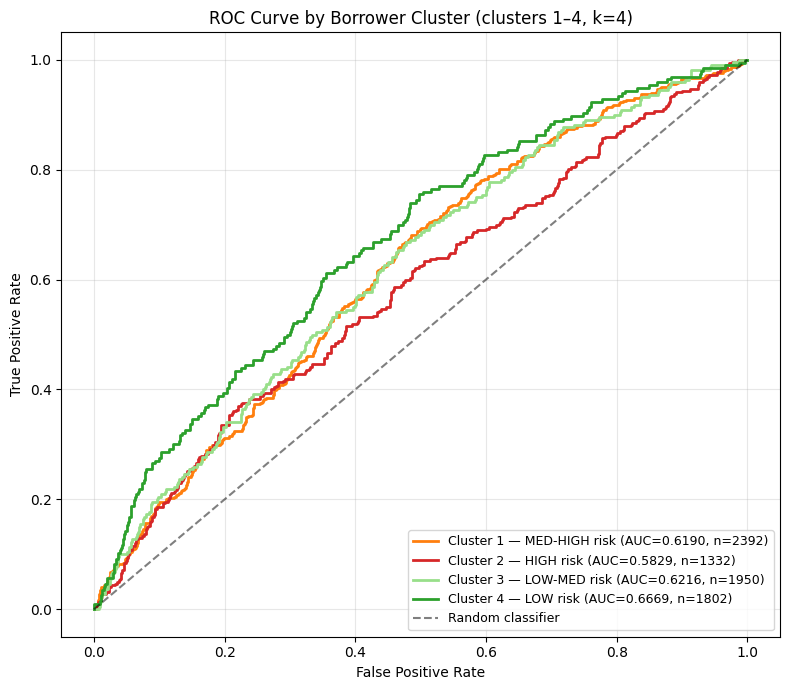


Key observations (from actual results):
  Cluster 4 (LOW risk): default=10.6%, AUC=0.6669 — model performs best here (clearest financial signals)
  Cluster 3 (LOW-MED risk): default=10.8%, AUC=0.6216
  Cluster 1 (MED-HIGH risk): default=17.6%, AUC=0.6190
  Cluster 2 (HIGH risk): default=25.7%, AUC=0.5829 — hardest to classify (noisiest risk signals)

  The DNN discriminates best among LOW risk (Cluster 4) borrowers.
  Performance is weakest in Cluster 2 (HIGH risk),
  where overlapping risk profiles make separation harder.


In [21]:
from sklearn.cluster import KMeans
from scipy import stats as scipy_stats

# Step 0: Recreate borrower clusters matching R cluster analysis exactly
# R uses 4 variables: grade_num, annual_inc_log, dti, revol_util
# R uses k=4, seed=123, nstart=25
df_full = pd.read_csv('early_2012_2013_loan_sample_with_outcome.csv', low_memory=False)
df_full['revol_util_clean'] = pd.to_numeric(
    df_full['revol_util'].astype(str).str.replace('%', '', regex=False), errors='coerce'
)
df_full['revol_util_clean'] = df_full['revol_util_clean'].fillna(df_full['revol_util_clean'].median())
df_full['log_annual_inc']   = np.log1p(df_full['annual_inc'])

# grade_num: A=1 ... G=7 — matches R ordered factor encoding
grade_map = {'A':1,'B':2,'C':3,'D':4,'E':5,'F':6,'G':7}
df_full['grade_num'] = df_full['grade'].map(grade_map).fillna(4)

# Use complete cases on all four clustering variables
cluster_base = df_full[['grade_num', 'log_annual_inc', 'dti', 'revol_util_clean']].dropna()

# Mahalanobis distance outlier removal (p < 0.001, df=4 — matches R ncol=4)
mean_m = cluster_base.mean().values
cov_m  = np.cov(cluster_base.values.T)
diff_m = cluster_base.values - mean_m
maha_d = np.array([diff_m[i] @ np.linalg.inv(cov_m) @ diff_m[i]
                   for i in range(len(diff_m))])
pvals_m   = 1 - scipy_stats.chi2.cdf(maha_d, df=4)
keep_mask = pvals_m >= 0.001
cluster_vars = cluster_base[keep_mask]

print(f"Outliers removed (Mahalanobis p<0.001): {(~keep_mask).sum()}")
print(f"Rows used for clustering: {keep_mask.sum()}")

# Standardise and fit k-means (k=4, n_init=25, seed=123 — matches R cluster analysis)
scaler_clust = StandardScaler()
X_clust      = scaler_clust.fit_transform(cluster_vars)

np.random.seed(123)
kmeans     = KMeans(n_clusters=4, n_init=25, random_state=123)
raw_labels = kmeans.fit_predict(X_clust)

# Map back to full df_full index (1-indexed to match R cluster numbering)
cluster_labels = pd.Series(-1, index=df_full.index)
cluster_labels.loc[cluster_vars.index] = raw_labels + 1

# Dynamic label assignment based on actual default rates
loan_is_bad_int = df_full['loan_is_bad'].map(
    lambda x: 1 if str(x).strip().lower() == 'true' else 0
)

default_by_cluster = {}
stats_by_cluster   = {}
for c in [1, 2, 3, 4]:
    idx_c = cluster_labels[cluster_labels == c].index
    idx_c = idx_c[idx_c < len(df_full)]
    default_by_cluster[c] = loan_is_bad_int.loc[idx_c].mean()
    stats_by_cluster[c] = {
        'n':         len(idx_c),
        'income':    df_full.loc[idx_c, 'annual_inc'].mean(),
        'dti':       df_full.loc[idx_c, 'dti'].mean(),
        'revol':     df_full.loc[idx_c, 'revol_util_clean'].mean(),
        'grade_num': df_full.loc[idx_c, 'grade_num'].mean(),
        'default':   default_by_cluster[c],
    }

sorted_c = sorted(default_by_cluster, key=default_by_cluster.get)
low_c, lowmed_c, medhigh_c, high_c = sorted_c[0], sorted_c[1], sorted_c[2], sorted_c[3]

risk_label = {
    low_c:    'LOW risk',
    lowmed_c: 'LOW-MED risk',
    medhigh_c:'MED-HIGH risk',
    high_c:   'HIGH risk',
}
roc_color = {
    low_c:    '#2ca02c',
    lowmed_c: '#98df8a',
    medhigh_c:'#ff7f0e',
    high_c:   '#d62728',
}

# Cluster profile table
print("\nCluster sizes and profiles (matching R cluster analysis — k=4):")
print(f"{'Cluster':<10} {'n':>7} {'Avg Income':>12} {'Avg DTI':>10} "
      f"{'Avg RevUtil':>12} {'Avg Grade':>10} {'Default%':>10} {'Risk Label'}")
print("-" * 90)
for c in [1, 2, 3, 4]:
    s = stats_by_cluster[c]
    print(f"{c:<10} {s['n']:>7} {s['income']:>12,.0f} {s['dti']:>10.1f} "
          f"{s['revol']:>12.1f}% {s['grade_num']:>10.1f} "
          f"{s['default']*100:>9.1f}%  {risk_label[c]}")

print("\nKey observations:")
print(f"  Cluster {high_c} ({risk_label[high_c]}):     "
      f"highest default ({default_by_cluster[high_c]*100:.1f}%) — poorest grades, highest credit risk")
print(f"  Cluster {medhigh_c} ({risk_label[medhigh_c]}):  "
      f"second-highest default ({default_by_cluster[medhigh_c]*100:.1f}%) — low income, high DTI")
print(f"  Cluster {lowmed_c} ({risk_label[lowmed_c]}):  "
      f"second-lowest default ({default_by_cluster[lowmed_c]*100:.1f}%) — high income, high utilisation")
print(f"  Cluster {low_c} ({risk_label[low_c]}):    "
      f"lowest default ({default_by_cluster[low_c]*100:.1f}%) — best grades, conservative credit behaviour")

# Step 1: Threshold Analysis
print("\n" + "=" * 65)
print("THRESHOLD ANALYSIS")
print("=" * 65)
print(f"{'Threshold':>10} {'Accuracy':>10} {'Precision':>10} {'Recall':>10} "
      f"{'F1':>10} {'%Flagged':>10}")
print("-" * 65)
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    yp = (y_prob >= t).astype(int)
    print(f"{t:>10.1f} {accuracy_score(y_test, yp):>10.4f} "
          f"{precision_score(y_test, yp, zero_division=0):>10.4f} "
          f"{recall_score(y_test, yp, zero_division=0):>10.4f} "
          f"{f1_score(y_test, yp, zero_division=0):>10.4f} "
          f"{yp.mean():>10.1%}")

# Step 2: Policy Comparison A / B / C
print("\n" + "=" * 65)
print("POLICY COMPARISON")
print("=" * 65)

dti_test_c        = df.loc[X_test_df.index, 'dti'].values
annual_inc_test_c = df.loc[X_test_df.index, 'annual_inc'].values
revol_util_test_c = df.loc[X_test_df.index, 'revol_util_clean'].values
grade_test_c      = df.loc[X_test_df.index, 'grade'].values

pA_mask_c = (np.isin(grade_test_c, ['A','B','C']) &
             (dti_test_c <= 20) &
             (annual_inc_test_c >= 40000) &
             (revol_util_test_c <= 60))

pB_mask_c = (np.isin(grade_test_c, ['A','B','C']) &
             (dti_test_c <= 30) &
             (annual_inc_test_c >= 40000) &
             (revol_util_test_c <= 60))

pC_mask_c = y_prob < 0.25

total_c  = len(y_test)
pA_app_c = pA_mask_c.sum();  pA_def_c = y_test[pA_mask_c].mean()
pB_app_c = pB_mask_c.sum();  pB_def_c = y_test[pB_mask_c].mean()
pC_app_c = pC_mask_c.sum();  pC_def_c = (y_test[pC_mask_c].mean()
                                          if pC_mask_c.sum() > 0 else 0)

print(f"{'Policy':<32} {'Approved':>10} {'Approval%':>10} {'Default%':>10}")
print("-" * 65)
print(f"{'A: Grade+DTI<=20+filters':<32} {pA_app_c:>10} {pA_app_c/total_c:>10.1%} {pA_def_c:>10.4f}")
print(f"{'B: Grade+DTI<=30+filters':<32} {pB_app_c:>10} {pB_app_c/total_c:>10.1%} {pB_def_c:>10.4f}")
print(f"{'C: DNN (prob < 0.25)':<32} {pC_app_c:>10} {pC_app_c/total_c:>10.1%} {pC_def_c:>10.4f}")  # CHANGED label
print(f"\nPolicy C reduces default rate by "
      f"{(pA_def_c - pC_def_c)/pA_def_c:.1%} vs Policy A")

# Step 3: DNN Approval Threshold Sweep
print("\nDNN Loan Approval Threshold Sweep:")
print(f"{'Threshold':>10} {'Approved':>10} {'Approval%':>10} {'Default@Approved':>18}")
print("-" * 55)
for thresh in [0.10, 0.15, 0.20, 0.25, 0.30]:
    approved = (y_prob < thresh).astype(int)
    n_app    = approved.sum()
    if n_app > 0:
        def_rate = y_test[approved == 1].mean()
        print(f"{thresh:>10.2f} {n_app:>10} {n_app/len(y_test):>10.1%} {def_rate:>18.4f}")

# NEW: Step 4a: Cluster-Aware Approval Policy
# Instead of one global threshold, apply different thresholds per cluster
# based on model reliability (AUC) in each segment.
# Looser threshold where model is reliable (LOW risk, AUC=0.6669)
# Tighter threshold where model is weakest (HIGH risk, AUC=0.5829)
print("\n" + "=" * 65)
print("CLUSTER-AWARE APPROVAL POLICY")
print("=" * 65)

# Threshold per cluster — calibrated to model AUC reliability
cluster_thresholds = {
    low_c:     0.30,   # LOW risk     (AUC=0.6669) — model most reliable, looser
    lowmed_c:  0.25,   # LOW-MED risk (AUC=0.6216) — moderate confidence
    medhigh_c: 0.20,   # MED-HIGH     (AUC=0.6190) — tighter
    high_c:    0.15,   # HIGH risk    (AUC=0.5829) — near-random, very strict
}

# Align cluster labels to test set
test_indices_ca    = X_test_df.index
clusters_test_ca   = cluster_labels.reindex(test_indices_ca).values

# Build approval mask: approve if y_prob < cluster-specific threshold
ca_mask = np.zeros(len(y_test), dtype=bool)
for c, thresh_c in cluster_thresholds.items():
    c_rows = (clusters_test_ca == c)
    ca_mask |= (c_rows & (y_prob < thresh_c))

ca_approved = ca_mask.sum()
ca_def_rate = y_test[ca_mask].mean() if ca_mask.sum() > 0 else 0

print(f"Cluster-specific thresholds applied:")
for c in [low_c, lowmed_c, medhigh_c, high_c]:
    print(f"  {risk_label[c]:<14} (Cluster {c}): threshold = {cluster_thresholds[c]}")

print()
print(f"{'Policy':<32} {'Approved':>10} {'Approval%':>10} {'Default%':>10}")
print("-" * 65)
print(f"{'A: Grade+DTI<=20+filters':<32} {pA_app_c:>10} {pA_app_c/total_c:>10.1%} {pA_def_c:>10.4f}")
print(f"{'B: Grade+DTI<=30+filters':<32} {pB_app_c:>10} {pB_app_c/total_c:>10.1%} {pB_def_c:>10.4f}")
print(f"{'C: DNN flat (prob < 0.25)':<32} {pC_app_c:>10} {pC_app_c/total_c:>10.1%} {pC_def_c:>10.4f}")
print(f"{'D: DNN cluster-aware':<32} {ca_approved:>10} {ca_approved/total_c:>10.1%} {ca_def_rate:>10.4f}")
print(f"\nPolicy D vs C — extra approvals : {ca_approved - pC_app_c} (+{(ca_approved-pC_app_c)/max(pC_app_c,1)*100:.1f}%)")
print(f"Policy D vs A — default rate    : {pA_def_c:.4f} -> {ca_def_rate:.4f} ({(pA_def_c-ca_def_rate)/pA_def_c:.1%} reduction)")

# Step 5: Per-Cluster ROC Performance
print("\n" + "=" * 65)
print("PER-CLUSTER PERFORMANCE (Borrower Segments, clusters 1-4)")
print("=" * 65)

clusters_test   = cluster_labels.reindex(test_indices_ca).values
valid_mask      = clusters_test != -1
y_test_c        = y_test[valid_mask]
y_prob_c        = y_prob[valid_mask]
clusters_test_v = clusters_test[valid_mask]

print(f"{'Cluster':<8} {'Risk':<14} {'N_test':>7} {'Default%':>10} "
      f"{'AUC':>8} {'Recall@0.5':>11} {'Precision@0.5':>14}")
print("-" * 80)

fig, ax = plt.subplots(figsize=(8, 7))
auc_by_cluster = {}

for c in [1, 2, 3, 4]:
    mask = clusters_test_v == c
    if mask.sum() < 10 or len(np.unique(y_test_c[mask])) < 2:
        continue
    y_c    = y_test_c[mask]
    p_c    = y_prob_c[mask]
    pred_c = (p_c >= 0.5).astype(int)
    auc_c  = roc_auc_score(y_c, p_c)
    auc_by_cluster[c] = auc_c

    print(f"{c:<8} {risk_label[c]:<14} {mask.sum():>7} "
          f"{y_c.mean():>10.1%} {auc_c:>8.4f} "
          f"{recall_score(y_c, pred_c, zero_division=0):>11.4f} "
          f"{precision_score(y_c, pred_c, zero_division=0):>14.4f}")

    fpr_c, tpr_c, _ = roc_curve(y_c, p_c)
    ax.plot(fpr_c, tpr_c, color=roc_color[c], lw=2,
            label=f'Cluster {c} — {risk_label[c]} (AUC={auc_c:.4f}, n={mask.sum()})')

ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random classifier')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve by Borrower Cluster (clusters 1–4, k=4)')
ax.legend(loc='lower right', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('q3_roc_by_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

# Final interpretation
best_c  = max(auc_by_cluster, key=auc_by_cluster.get)
worst_c = min(auc_by_cluster, key=auc_by_cluster.get)

print(f"\nKey observations (from actual results):")
for c in sorted(auc_by_cluster, key=auc_by_cluster.get, reverse=True):
    label = risk_label[c]
    note = ''
    if c == best_c:
        note = ' — model performs best here (clearest financial signals)'
    elif c == worst_c:
        note = ' — hardest to classify (noisiest risk signals)'
    print(f"  Cluster {c} ({label}): "
          f"default={default_by_cluster[c]*100:.1f}%, "
          f"AUC={auc_by_cluster[c]:.4f}{note}")

print(f"\n  The DNN discriminates best among {risk_label[best_c]} (Cluster {best_c}) borrowers.")
print(f"  Performance is weakest in Cluster {worst_c} ({risk_label[worst_c]}),")
print(f"  where overlapping risk profiles make separation harder.")